In [1]:
!pip install mitsuba

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 62.6/62.6 MB 44.2 MB/s  0:00:016m0:00:010:01
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 5.0/5.0 MB 97.5 MB/s  0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2/2 [mitsuba]m1/2 [mitsuba]


In [2]:
import mitsuba as mi
import matplotlib.pyplot as plt
import math

In [3]:
mi.set_variant('cuda_ad_spectral')

In [6]:
!wget https://raw.githubusercontent.com/gnomeby/canvas3D/refs/heads/master/teapot.ply

--2026-11-12 16:13:57--  https://raw.githubusercontent.com/gnomeby/canvas3D/refs/heads/master/teapot.ply
Resolving raw.githubusercontent.com (raw.githubusercontent.com)... 185.199.108.133, 185.199.109.133, 185.199.110.133, ...
Connecting to raw.githubusercontent.com (raw.githubusercontent.com)|185.199.108.133|:443... connected.
HTTP request sent, awaiting response... 200 OK
Length: 63132 (62K) [text/plain]
Saving to: ‘teapot.ply’

teapot.ply          100%[===================>]  61.65K  --.-KB/s    in 0.008s  

2026-11-12 16:13:57 (7.10 MB/s) - ‘teapot.ply’ saved [63132/63132]



In [58]:
scene = mi.load_dict({
    'type': 'scene',
    'integrator': {'type': 'path'},
    'light': {'type': 'constant'},
    'teapot': {
        'type': 'ply',
        'filename': 'teapot.ply',
        'to_world': mi.ScalarTransform4f.scale(0.5).translate([0, 0, 1.5]).rotate(axis=[1, 0, 0], angle=-90),
        'bsdf': {'type': 'diffuse', 'reflectance': {'type': 'rgb', 'value': [0.1, 0.0, 0.0]}}
    },
})


In [70]:
def spherical_positions(width: int, height: int, N: int, x: float, y: float, z: float, radius: float):
    sensors = []
    phi = np.pi * (3. - np.sqrt(5.))
    
    for i in range(N):
        y_coord = 1 - (i / float(N - 1)) * 2
        radius_at_y = np.sqrt(1 - y_coord * y_coord)
        theta = phi * i
        
        px = np.cos(theta) * radius_at_y
        py = y_coord
        pz = np.sin(theta) * radius_at_y
        
        cam_pos = mi.ScalarPoint3f(
            x + px * radius,
            y + py * radius,
            z + pz * radius
        )
        
        sensor = {
            "type": "perspective",
            "fov": 70,
            "to_world": mi.ScalarTransform4f.look_at(
                origin=cam_pos,
                target=mi.ScalarPoint3f(x, y, z),
                up=mi.ScalarVector3f(0, 1, 0)
            ),
            'film': {
                'type': 'hdrfilm',
                'width': width,
                'height': height,
            }
        }
        sensors.append(sensor)
    
    return sensors

def use_spectrum(sensors: List[dict]):
    wavelengths = list(range(450, 650, 10))
    res = []

    for rgb_sensor in sensors:
        width, height = rgb_sensor['film']['width'], rgb_sensor['film']['height']
        wavelength_sensors = dict()
        wavelength_sensors['rgb'] = rgb_sensor

        for wavelength in wavelengths:
            film = {
                'type': 'specfilm',
                'width': width,
                'height': height,
                'channel1': {
                    'type': 'irregular',
                    'wavelengths': f'{wavelength}, {wavelength + 1}',
                    'values': '1.0, 1.0',
                },
            }
            wavelength_sensors[wavelength] = {**rgb_sensor, 'film': film}
        res.append(wavelength_sensors)
    return res

In [71]:
scene = mi.load_dict(scene_dict)

rgb_cfgs = spherical_positions(640, 480, 50, 0, 0, 0, 5)

spectral_cfgs = use_spectrum(rgb_cfgs)

sensors = []
for group in spectral_cfgs:
    loaded_group = {k: mi.load_dict(v) for k, v in group.items()}
    sensors.append(loaded_group)

In [72]:
images = list()
for sensorWavelength in sensors:
    spectrum = dict()
    for wavelength, sensor in sensorWavelength.items():
        spectrum[wavelength] = mi.render(scene, sensor=sensor, spp=256)
    images.append(spectrum)



In [73]:
def split_train_val(images, val_every=8):
    train_images = []
    val_images = []
    
    for i, spectrum in enumerate(images):
        if i % val_every == 0:
            val_images.append(spectrum)
        else:
            train_images.append(spectrum)
    
    return train_images, val_images

In [ ]:
train, val = split_train_val(images)

In [75]:
import os
import json

def save_split_exr(images, split_name, base_dir="my_scene", val_every=8):
    os.makedirs(base_dir, exist_ok=True)
    frames = []
    wavelengths = [k for k in images[0].keys() if k != 'rgb']

    for idx, spectrum in enumerate(images):
        is_val = (idx % val_every == 0)
        if (split_name == 'val' and not is_val) or (split_name == 'train' and is_val):
            continue

        frame_name = f"r_{idx:04d}"

        rgb_dir = os.path.join(base_dir, "rgb", split_name)
        os.makedirs(rgb_dir, exist_ok=True)
        rgb = spectrum['rgb']
        mi.Bitmap(rgb).write(os.path.join(rgb_dir, f"{frame_name}.exr"))

        for wl in wavelengths:
            wl_dir = os.path.join(base_dir, str(wl), split_name)
            os.makedirs(wl_dir, exist_ok=True)
            img = spectrum[wl]
            if img.ndim == 3:
                img = img[..., 0]
            mi.Bitmap(img).write(os.path.join(wl_dir, f"{frame_name}.exr"))

        frames.append({
            "file_path": f"./rgb/{split_name}/{frame_name}.exr",
            "hyperspectral_file_path": f"./{wavelengths[0]}/{split_name}/{frame_name}.exr"
        })

    with open(os.path.join(base_dir, f"transforms_{split_name}.json"), "w") as f:
        json.dump({"frames": frames}, f, indent=4)

In [76]:
save_split_exr(train,'train')
save_split_exr(val,'val')

In [61]:
import numpy as np
import math
import matplotlib.pyplot as plt

def show_images(images: dict, gamma: float = 2.2, cols: int = 4, cmap=None):
    items = list(images.items())
    n = len(items)
    cols = min(cols, n)
    rows = math.ceil(n / cols)

    fig, axes = plt.subplots(rows, cols, figsize=(3 * cols, 3 * rows), squeeze=False)

    for ax, (title, image) in zip(axes.flat, items):
        img = np.asarray(image, dtype=np.float64)

        img = np.clip(img, 0.0, 1.0)

        img_g = np.power(img, 1.0 / gamma)

        ax.imshow(img_g, cmap=cmap, vmin=0.0, vmax=1.0)
        ax.set_title(title)
        ax.axis("off")

    for ax in axes.flat[n:]:
        ax.axis("off")

    fig.tight_layout()
    plt.show()

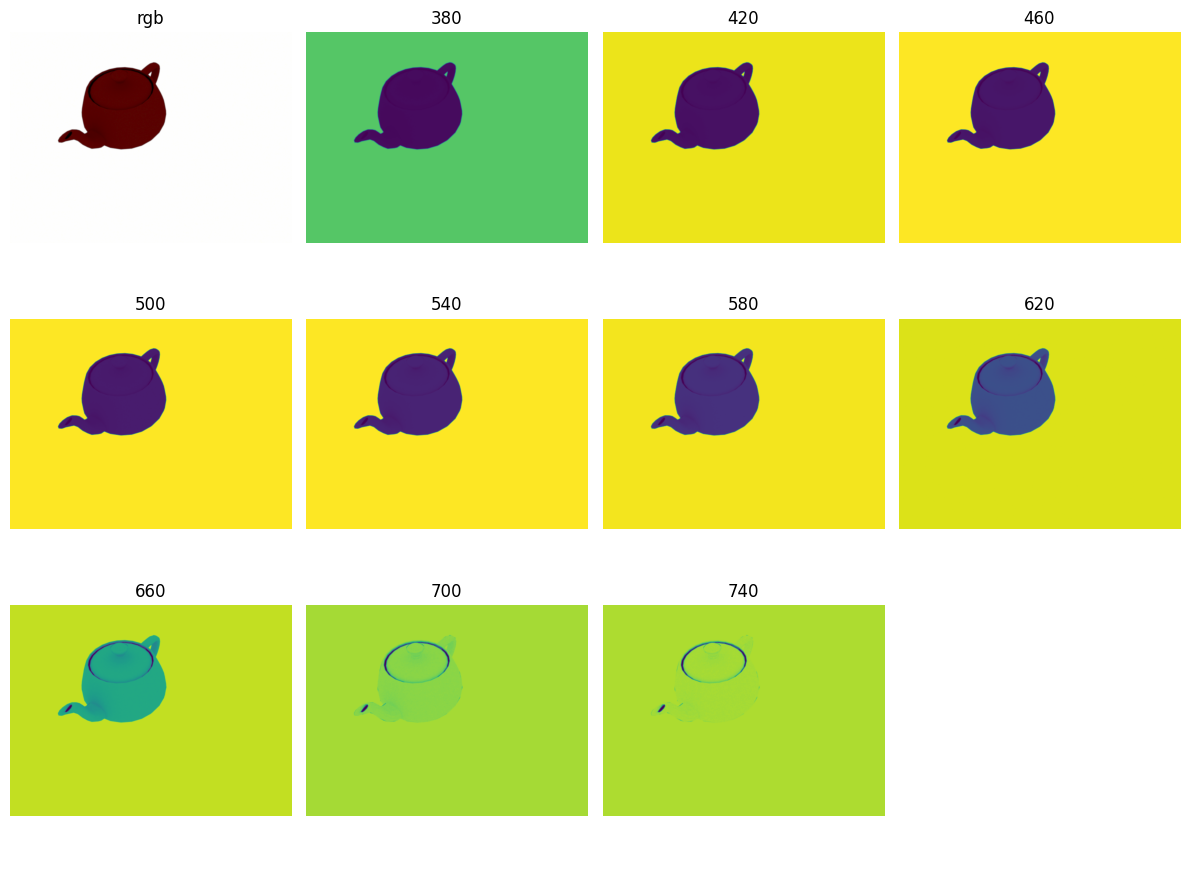

In [66]:
show_images(images[5])